# Modelo no supervisado — sismos de Santander

Este cuaderno agrupa los **municipios** de Santander según cómo se comportan los sismos.

- Lee el dataset ya limpio: `datos/processed/dataset_limpio.csv`.
- Usa la ventana **2006–2026** que eligió el equipo.
- Arma **k=4 grupos**: Bajo, Moderado, Alto y Muy alto.
- Guarda los CSV en `datosNoSup/` y la caché en esta misma carpeta.

Funciona desde cualquier carpeta: el cuaderno busca solo la raíz del repo. En Colab, sube el CSV (y el de fallas) a `datos/processed/`.

La primera corrida entrena y guarda una **caché** (`modelo_no_supervisado.joblib`); las siguientes la cargan y terminan en segundos.


In [1]:
import hashlib
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from scipy import stats
from sklearn.preprocessing import RobustScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.mixture import GaussianMixture
from sklearn.metrics import (silhouette_score, davies_bouldin_score,
                             calinski_harabasz_score, adjusted_rand_score)
import joblib

# Busca la raíz del repo: sube carpetas hasta encontrar "datos/processed".
RAIZ = Path.cwd()
while not (RAIZ / "datos" / "processed").exists() and RAIZ.parent != RAIZ:
    RAIZ = RAIZ.parent

RUTA_EVENTOS = RAIZ / "datos/processed/dataset_limpio.csv"
RUTA_FALLAS = RAIZ / "datos/processed/fallas_santander.geojson"
CARPETA = RAIZ / "modelos/no_supervisado"
SUBCARPETA = CARPETA / "datosNoSup"   # aquí quedan los CSV del modelo
RUTA_CACHE = CARPETA / "modelo_no_supervisado.joblib"

ANIO_INICIO = 2006   # ventana elegida por el equipo
MIN_EVENTOS = 15     # municipios con menos sismos no entran
K_FINAL = 4          # Bajo, Moderado, Alto, Muy alto
SEMILLA = 42
np.random.seed(SEMILLA)

if not RUTA_EVENTOS.exists():
    (RAIZ / "datos" / "processed").mkdir(parents=True, exist_ok=True)
    print("No encontré", RUTA_EVENTOS)
    print("Si estás en Colab: sube dataset_limpio.csv y fallas_santander.geojson a datos/processed/")
else:
    print("Raíz del repo:", RAIZ)

def md5_archivo(ruta):
    # Huella del archivo: sirve para saber si los datos cambiaron desde el último entrenamiento.
    return hashlib.md5(ruta.read_bytes()).hexdigest() if ruta.exists() else None

HUELLA = (md5_archivo(RUTA_EVENTOS), md5_archivo(RUTA_FALLAS), (ANIO_INICIO, MIN_EVENTOS, K_FINAL, SEMILLA))

paquete = None
if RUTA_CACHE.exists():
    try:
        candidato = joblib.load(RUTA_CACHE)
        if candidato.get("huella") == HUELLA:
            paquete = candidato
            print("Caché cargada: no se reentrena")
        else:
            print("La caché no coincide con los datos: se reentrena")
    except Exception as e:
        print("No pude leer la caché, se reentrena:", e)
else:
    print("Sin caché: esta corrida entrena")


Raíz del repo: C:\Users\damez\Downloads\Hackaton\Hackathon-CIAI-UTSmart-2026
Caché cargada: no se reentrena


## 1. Cargar los datos

Leemos solo el archivo procesado (nada de crudos). Ojo: 2014–2017 no tiene datos porque ese bloque no está descargado.


In [2]:
df = pd.read_csv(RUTA_EVENTOS, parse_dates=["fecha"])

print("Tipos de magnitud en todo el dataset:")
print(df["tipo_mag"].value_counts().to_string())

# Nos quedamos con la ventana del equipo y con la magnitud Ml (casi todos los sismos vienen así).
df = df[df["fecha"].dt.year >= ANIO_INICIO].copy()
df = df[df["tipo_mag"] == "Ml"].copy()

print("\nEventos desde", ANIO_INICIO, ":", len(df))
print("Fechas:", df["fecha"].min().date(), "->", df["fecha"].max().date())
print("Municipios:", df["municipio"].nunique())


Tipos de magnitud en todo el dataset:
tipo_mag
Ml      173844
Mw        1179
Otro       159
Mb           3

Eventos desde 2006 : 144456
Fechas: 2006-01-01 -> 2026-10-13
Municipios: 87


## 2. Variables por municipio

Resumimos cada municipio en 20 variables: cuántos sismos tiene, qué tan grandes, qué tan profundos, etc. Las tasas se calculan con los años que sí tienen datos. (Si hay caché, esta parte se salta.)


In [3]:
def haversine(lat1, lon1, lat2, lon2):
    # Distancia en km entre dos puntos del planeta.
    R = 6371.0
    la1, lo1, la2, lo2 = map(np.radians, [lat1, lon1, lat2, lon2])
    a = np.sin((la2 - la1) / 2) ** 2 + np.cos(la1) * np.cos(la2) * np.sin((lo2 - lo1) / 2) ** 2
    return 2 * R * np.arcsin(np.sqrt(a))

NIDO_LAT, NIDO_LON = 6.8, -73.1   # nido sísmico de Bucaramanga (aprox.)

if paquete is None:
    df["anio"] = df["fecha"].dt.year
    anios = df["anio"].nunique()
    df["es_m3"] = (df["mag"] >= 3).astype(int)
    df["es_m4"] = (df["mag"] >= 4).astype(int)
    df["energia"] = 10 ** (1.5 * df["mag"] + 4.8)   # energía liberada (regla de Gutenberg-Richter)
    df["reciente"] = (df["fecha"] >= df["fecha"].max() - pd.DateOffset(years=5)).astype(int)
    df["sup"] = (df["prof_km"] < 30).astype(int)
    df["inter"] = df["prof_km"].between(30, 150).astype(int)
    df["pro"] = (df["prof_km"] >= 150).astype(int)

    g = df.groupby("municipio")
    F = pd.DataFrame({
        "n_sismos": g.size(),
        "sismos_x_anio": g.size() / anios,
        "mag_media": g["mag"].mean(),
        "mag_max": g["mag"].max(),
        "mag_std": g["mag"].std(),
        "mag_p90": g["mag"].quantile(0.90),
        "pct_m3_mas": g["es_m3"].mean(),
        "pct_m4_mas": g["es_m4"].mean(),
        "log_energia": np.log10(g["energia"].sum()),
        "prof_media": g["prof_km"].mean(),
        "prof_std": g["prof_km"].std(),
        "pct_superficial": g["sup"].mean(),
        "pct_intermedia": g["inter"].mean(),
        "pct_profunda": g["pro"].mean(),
        "rms_medio": g["rms_seg"].mean(),
        "gap_medio": g["gap_grados"].mean(),
        "fases_medias": g["n_fases"].mean(),
        "frac_reciente": g["reciente"].mean(),
        "lat_centro": g["lat"].mean(),
        "lon_centro": g["lon"].mean(),
    })
    F["dist_nido_km"] = haversine(F["lat_centro"], F["lon_centro"], NIDO_LAT, NIDO_LON)

    F = F[F["n_sismos"] >= MIN_EVENTOS].copy()
    F = F.fillna(F.median(numeric_only=True))
    print("Municipios con", MIN_EVENTOS, "o más sismos:", len(F))
else:
    F = paquete["F"]
    print("Municipios cargados de la caché:", len(F))

F.head()


Municipios cargados de la caché: 82


,n_sismos,sismos_x_anio,mag_media,mag_max,mag_std,mag_p90,pct_m3_mas,pct_m4_mas,log_energia,prof_media,...,gap_medio,fases_medias,frac_reciente,lat_centro,lon_centro,dist_nido_km,dist_falla_km,grupo_num,indice_actividad,grupo
municipio,,,,,,,,,,,,,,,,,,,,,
AGUADA,58,3.411765,1.717241,2.6,0.364734,2.13,0.000000,0.000000,9.500800,121.764138,...,129.189655,15.879310,0.327586,6.180379,-73.524845,83.367653,1.888161,1,-0.784823,Moderado
ALBANIA,281,16.529412,1.776512,3.3,0.393269,2.20,0.014235,0.000000,10.520621,104.119181,...,111.153025,16.056940,0.366548,5.767843,-73.869441,142.844487,12.204924,1,-0.388564,Moderado
ARATOCA,1029,60.529412,1.805151,4.1,0.310332,2.20,0.002915,0.001944,11.363704,138.310224,...,177.265306,10.587949,0.586978,6.734215,-73.027315,10.859293,2.289540,2,0.187664,Muy alto
BARBOSA,139,8.176471,1.709353,3.4,0.362738,2.10,0.014388,0.000000,10.278827,115.747122,...,122.338129,11.949640,0.287770,5.935971,-73.627813,112.394899,1.353376,1,-0.393213,Moderado
BARICHARA,1639,96.411765,1.689933,3.4,0.239051,2.00,0.000610,0.000000,10.766715,138.563197,...,163.142160,9.272727,0.500915,6.677984,-73.210401,18.240259,3.769342,1,-0.286768,Moderado


## 3. Fallas geológicas (si están)

Si existe `fallas_santander.geojson`, agregamos la distancia del centro del municipio a la falla visible más cercana. Es una aproximación.


In [4]:
if paquete is None:
    if RUTA_FALLAS.exists():
        geo = json.loads(RUTA_FALLAS.read_text(encoding="utf-8"))
        puntos = []
        for f in geo["features"]:
            for parte in f["geometry"]["coordinates"]:
                puntos.extend(parte)
        puntos = np.array(puntos)

        def dist_min_falla(lat, lon):
            return float(haversine(lat, lon, puntos[:, 1], puntos[:, 0]).min())

        F["dist_falla_km"] = [dist_min_falla(la, lo) for la, lo in zip(F["lat_centro"], F["lon_centro"])]
        print("Fallas cargadas:", len(puntos), "puntos")
    else:
        puntos = None
        print("No hay archivo de fallas; seguimos sin esa variable")
else:
    puntos = paquete.get("puntos")
    print("Fallas cargadas de la caché" if puntos is not None else "La caché no tiene fallas")


Fallas cargadas de la caché


## 4. Preparar las variables

Escalamos los números (para que ninguno pese más que otro por su tamaño) y resumimos con PCA.


In [5]:
if paquete is None:
    COLS_LOG = [c for c in ["n_sismos", "sismos_x_anio", "dist_nido_km", "dist_falla_km"] if c in F]
    X = F.copy()
    X[COLS_LOG] = np.log1p(X[COLS_LOG])

    # Las coordenadas se quedan para el mapa, no entran al modelo.
    COLS_MODELO = [c for c in X.columns if c not in ("lat_centro", "lon_centro")]

    escalador = RobustScaler()
    Xs = np.clip(escalador.fit_transform(X[COLS_MODELO]), -5, 5)

    pca = PCA(n_components=0.90, random_state=SEMILLA)
    Z = pca.fit_transform(Xs)
else:
    COLS_LOG = paquete["cols_log"]
    COLS_MODELO = paquete["columnas"]
    escalador = paquete["escalador"]
    pca = paquete["pca"]
    Z = paquete["Z"]

print("Variables del modelo:", len(COLS_MODELO))
print("Componentes PCA (90% de la información):", Z.shape[1])


Variables del modelo: 20
Componentes PCA (90% de la información): 6


## 5. Comparar modelos (evidencia)

Probamos KMeans, Ward y GMM con k de 2 a 8. Esto queda como evidencia para el jurado. Nosotros usamos **k=4 fijo** (lo acordó el equipo).


In [6]:
if paquete is None:
    def ajustar(nombre, k, datos):
        if nombre == "KMeans":
            return KMeans(n_clusters=k, n_init=10, random_state=SEMILLA).fit_predict(datos)
        if nombre == "Ward":
            return AgglomerativeClustering(n_clusters=k, linkage="ward").fit_predict(datos)
        return GaussianMixture(n_components=k, covariance_type="diag", n_init=3, random_state=SEMILLA).fit_predict(datos)

    def estabilidad(nombre, k, datos, repes=10, frac=0.8):
        # ¿Los grupos se mantienen si quitamos el 20% de los municipios al azar?
        rng = np.random.default_rng(SEMILLA)
        base = ajustar(nombre, k, datos)
        aris = []
        for _ in range(repes):
            idx = rng.choice(len(datos), int(frac * len(datos)), replace=False)
            aris.append(adjusted_rand_score(base[idx], ajustar(nombre, k, datos[idx])))
        return float(np.mean(aris))

    filas = []
    for nombre in ["KMeans", "Ward", "GMM"]:
        for k in range(2, 9):
            lab = ajustar(nombre, k, Z)
            filas.append({
                "modelo": nombre, "k": k,
                "silueta": silhouette_score(Z, lab),
                "davies": davies_bouldin_score(Z, lab),
                "calinski": calinski_harabasz_score(Z, lab),
                "estabilidad": estabilidad(nombre, k, Z),
            })
    comparacion = pd.DataFrame(filas)
else:
    comparacion = paquete["comparacion"]

comparacion.round(3)


,modelo,k,silueta,davies,calinski,estabilidad
0,KMeans,2,0.331,1.331,30.429,0.976
1,KMeans,3,0.251,1.382,29.281,0.519
2,KMeans,4,0.275,1.174,29.543,0.758
3,KMeans,5,0.258,1.282,26.755,0.697
4,KMeans,6,0.259,1.206,26.359,0.590
5,KMeans,7,0.281,1.096,26.019,0.645
6,KMeans,8,0.274,1.103,25.762,0.584
7,Ward,2,0.382,1.050,27.019,0.895
8,Ward,3,0.207,1.516,25.482,0.487
9,Ward,4,0.238,1.309,26.531,0.639


## 6. Armar los grupos

El índice de actividad mezcla frecuencia, energía, tamaño máximo y superficialidad. Un municipio con pocos sismos pero **muy superficiales** también cuenta como peligroso.


In [7]:
if paquete is None:
    modelo_final = KMeans(n_clusters=K_FINAL, n_init=10, random_state=SEMILLA)
    F["grupo_num"] = modelo_final.fit_predict(Z)

    IND = ["sismos_x_anio", "log_energia", "mag_max", "pct_m4_mas", "pct_superficial"]
    zs = (F[IND] - F[IND].mean()) / F[IND].std()
    F["indice_actividad"] = zs.mean(axis=1)

    # Los grupos se ordenan de menor a mayor actividad y se etiquetan.
    orden = F.groupby("grupo_num")["indice_actividad"].mean().sort_values().index
    nombres = ["Bajo", "Moderado", "Alto", "Muy alto"]
    etiquetas = {g: nombres[i] for i, g in enumerate(orden)}
    F["grupo"] = F["grupo_num"].map(etiquetas)
else:
    modelo_final = paquete["modelo_final"]
    etiquetas = paquete["etiquetas"]
    print("Grupos cargados de la caché")

print("Municipios por grupo:")
print(F["grupo"].value_counts().to_string())

perfil = F.groupby("grupo")[COLS_MODELO].median().round(2)
perfil.insert(0, "municipios", F.groupby("grupo").size())
perfil.T


Grupos cargados de la caché
Municipios por grupo:
grupo
Moderado    37
Bajo        23
Muy alto    14
Alto         8


grupo,Alto,Bajo,Moderado,Muy alto
municipios,8.00,23.00,37.00,14.00
n_sismos,34.00,57.00,430.00,804.00
sismos_x_anio,2.00,3.35,25.29,47.29
mag_media,1.64,1.88,1.68,1.80
mag_max,2.95,3.30,3.60,4.45
mag_std,0.45,0.46,0.39,0.47
mag_p90,2.20,2.47,2.10,2.35
pct_m3_mas,0.01,0.02,0.01,0.03
pct_m4_mas,0.00,0.00,0.00,0.00
log_energia,9.62,10.09,10.80,11.82


## 7. ¿Qué variables separan los grupos?

Usamos Kruskal-Wallis (una prueba estadística simple) y miramos qué variables cambian más entre grupos.


In [8]:
filas_imp = []
for c in COLS_MODELO:
    muestras = [d[c].values for _, d in F.groupby("grupo")]
    if all(np.std(m) == 0 for m in muestras):
        continue
    H, p = stats.kruskal(*muestras)
    filas_imp.append((c, H / (len(F) - 1), p))
importancia = pd.DataFrame(filas_imp, columns=["variable", "eta2", "p"]).sort_values("eta2", ascending=False)
importancia.head(12).round(4)


,variable,eta2,p
7,pct_m4_mas,0.6858,0.0
12,pct_intermedia,0.6427,0.0
13,pct_profunda,0.6143,0.0
2,mag_media,0.5440,0.0
15,gap_medio,0.5299,0.0
9,prof_media,0.4693,0.0
0,n_sismos,0.4647,0.0
1,sismos_x_anio,0.4647,0.0
5,mag_p90,0.4347,0.0
10,prof_std,0.4326,0.0


## 8. Gráficos


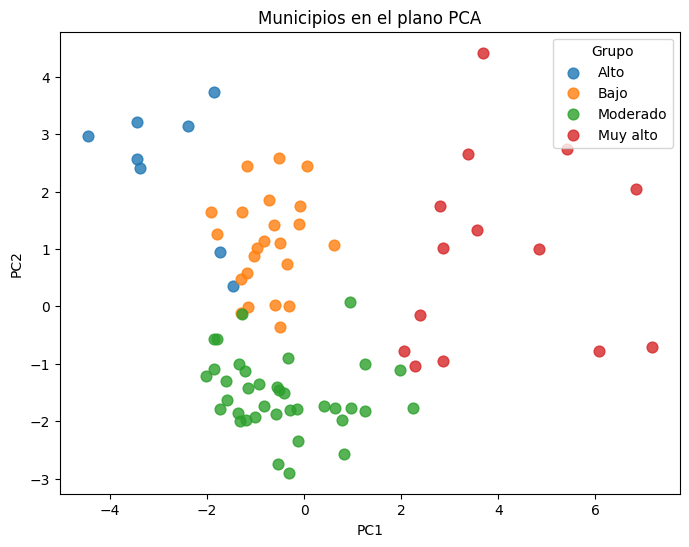

In [9]:
fig, ax = plt.subplots(figsize=(8, 6))
for grupo, d in F.groupby("grupo"):
    donde = [F.index.get_loc(m) for m in d.index]
    ax.scatter(Z[donde, 0], Z[donde, 1], s=60, label=grupo, alpha=.8)
ax.set_xlabel("PC1"); ax.set_ylabel("PC2")
ax.legend(title="Grupo"); ax.set_title("Municipios en el plano PCA")
plt.show()


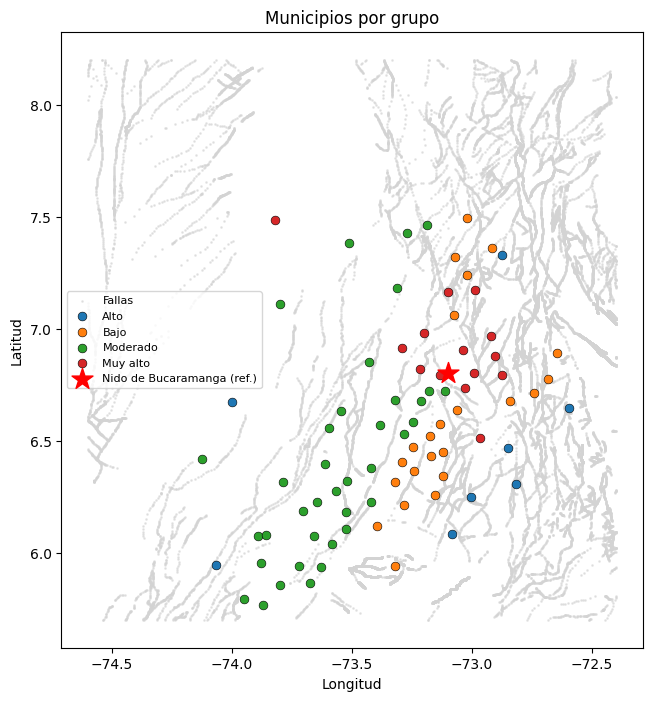

In [10]:
fig, ax = plt.subplots(figsize=(7.5, 8))
if puntos is not None:
    ax.scatter(puntos[:, 0], puntos[:, 1], s=1, c="lightgray", alpha=.5, label="Fallas")
for grupo, d in F.groupby("grupo"):
    ax.scatter(d["lon_centro"], d["lat_centro"], s=40, label=grupo, edgecolor="k", linewidth=.4)
ax.scatter(NIDO_LON, NIDO_LAT, marker="*", s=250, c="red", label="Nido de Bucaramanga (ref.)")
ax.set_xlabel("Longitud"); ax.set_ylabel("Latitud")
ax.legend(fontsize=8); ax.set_title("Municipios por grupo")
plt.show()


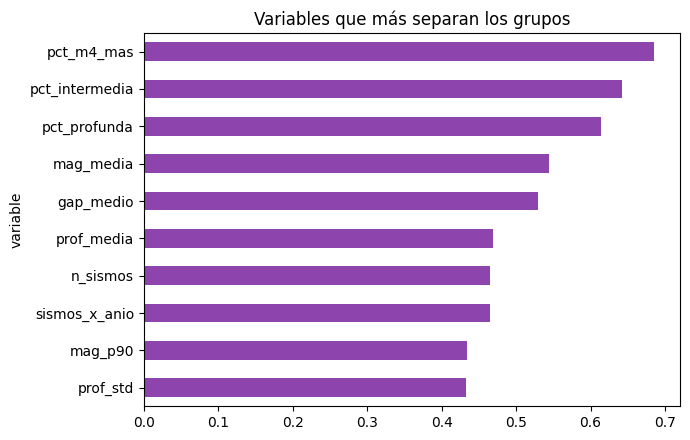

In [11]:
fig, ax = plt.subplots(figsize=(7, 4.5))
importancia.head(10).iloc[::-1].plot.barh(x="variable", y="eta2", legend=False, color="#8e44ad", ax=ax)
ax.set_title("Variables que más separan los grupos")
plt.tight_layout(); plt.show()


## 9. Guardar resultados

Los CSV quedan en `modelos/no_supervisado/datosNoSup/` y la caché en `modelos/no_supervisado/`. El `.joblib` es a la vez la **caché** y el artefacto del modelo: la próxima corrida carga de ahí y no reentrena. Si quieres forzar reentreno, bórralo.


In [12]:
CARPETA.mkdir(parents=True, exist_ok=True)
SUBCARPETA.mkdir(parents=True, exist_ok=True)
F[["grupo", "indice_actividad"]].to_csv(SUBCARPETA / "grupo_por_municipio.csv", encoding="utf-8")
perfil.to_csv(SUBCARPETA / "perfil_grupos.csv", encoding="utf-8")
comparacion.to_csv(SUBCARPETA / "comparacion_modelos.csv", index=False, encoding="utf-8")
importancia.to_csv(SUBCARPETA / "importancia_variables.csv", index=False, encoding="utf-8")

# Paquete completo: tabla por municipio + preprocesado + modelo + comparación + huella.
joblib.dump({
    "huella": HUELLA,
    "fecha_entrenamiento": str(pd.Timestamp.now()),
    "F": F,
    "columnas": COLS_MODELO,
    "cols_log": COLS_LOG,
    "escalador": escalador,
    "pca": pca,
    "Z": Z,
    "modelo_final": modelo_final,
    "etiquetas": etiquetas,
    "comparacion": comparacion,
    "puntos": puntos,
}, CARPETA / "modelo_no_supervisado.joblib")
print("Listo. Archivos guardados en", CARPETA)
print(F["grupo"].value_counts().to_string())


Listo. Archivos guardados en C:\Users\damez\Downloads\Hackaton\Hackathon-CIAI-UTSmart-2026\modelos\no_supervisado
grupo
Moderado    37
Bajo        23
Muy alto    14
Alto         8


## 10. Para el pitch

- Encontramos dos tipos de peligro: **Muy alto** = mucha actividad (zona del nido sísmico, sismos profundos); **Alto** = pocos sismos pero superficiales (más dañinos).
- Límites honestos: falta 2014–2017, falta población/vivienda (DANE) y la distancia a fallas es aproximada.
